# Heart Disease Prediction
**By: Kosisochukwu Caleb Nwatu**

This project is aimed towards predicting the possiblity of heart disease in a patient using machine learning models. The dataset used has 21 columns, 20 columns are the feauture we use to determine our target column. The target column tells us if a patient is prone to heart disease condition.

In [196]:
#Import our libries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder

np.random.seed(42)  # Set random seed for reproducibility


**1.0 Load our dataset:**
    The first step is to download our dataset to our local machine.

In [197]:
# # Download dataset latest version
# path = kagglehub.dataset_download("oktayrdeki/heart-disease")

# print("Path to dataset files:", path)

In [198]:
# Load the dataset
path = (r'C:\Users\USER\.cache\kagglehub\datasets\oktayrdeki\heart-disease\versions\1')
df = pd.read_csv(f'{path}/heart_disease.csv')

**2.0 Analyse our Data set:**
    The next thing is to get familiar with our dataset. Getting knowledgeable about the structure of our data (shape), it's datatype, missing values and so on. Below is a data dictionary which explains what each column entails. 

****Data Dictionary****
| S/N | Mode | Meaning |
|---|---|---|
| 1 | Age | The age of the individual in years. |
| 2 | Gender | Biological sex of the individual (e.g., Male, Female). |
| 3 | Blood Pressure | Resting blood pressure reading (typically Systolic/Diastolic in mmHg). |
| 4 | Cholesterol Level | Total blood cholesterol level measured in mg/dL. |
| 5 | Exercise Habits | Frequency or intensity of physical activity. |
| 6 | Smoking | Tobacco use status. |
| 7 | Family Heart Disease | Indicator for genetic or familial history of cardiovascular issues. |
| 8 | Diabetes | Clinical diagnosis status of diabetes. |
| 9 | BMI | Body Mass Index value calculated as \(\text{kg/m}^{2}\). |
| 10 | High Blood Pressure | Binary flag indicating clinical hypertension. |
| 11 | Low HDL Cholesterol. | Flag indicating if "good" cholesterol falls below optimal safety limits. |
| 12 | High LDL Cholesterol | Flag indicating if "bad" cholesterol exceeds healthy target limits. |
| 13 | Alcohol Consumption | Self-reported intake level classification (e.g., Low, Moderate, High). |
| 14 | Stress Level | Measured psychological stress metric (e.g., scale or Low/Medium/High). |
| 15 | Sleep Hours | Average hours of rest obtained per 24-hour cycle. |
| 16 | Sugar Consumption | Estimated daily dietary sugar intake in grams. |
| 17 | Triglyceride Level | Fasting lipid panel triglyceride measurement in mg/dL. |
| 18 | Fasting Blood Sugar | Serum glucose level measured post-fasting (mg/dL). |
| 19 | CRP Level | C-Reactive Protein concentration; marker for vascular inflammation (mg/L). |
| 20 | Homocysteine Level | Amino acid concentration indicating cardiovascular risk profiles (µmol/L). |
| 21 | Heart Disease Status | Target Variable: Presence (1/Yes) or absence (0/No) of heart disease. |

In [199]:
print(f'Dataset shape :{df.shape}') #Discover our datasets dimension (number of Rows and Columns)

Dataset shape :(10000, 21)


In [200]:
print('First three(3) rows :')
df.head(3) # Display the first few rows of the dataset

First three(3) rows :


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No


In [201]:
#Lets find out some information about our dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption   

Some values are missing from our dataset and the datatype of some columns are made up of floats while others are made up of strings. Next is making sure each column has the right datatype and fix any if mistake is detected. In our dataset each column has the right datatype, this was confirmed by cross-examining each name with the few rows of data displayed above.

In [202]:
df.duplicated().sum() #Check for duplicate rows in the dataset
# since there are no duplicate rows, we can proceed with our analysis

np.int64(0)

Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

Percentage distribution of the target variable:
Heart Disease Status
No     80.0
Yes    20.0
Name: proportion, dtype: float64


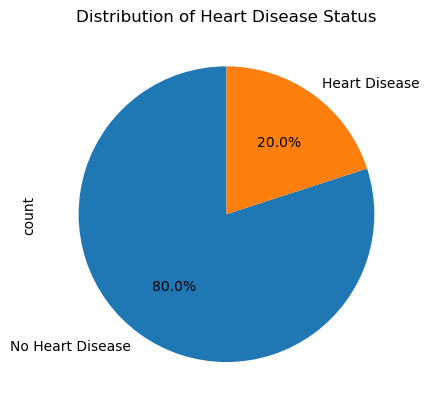

In [203]:
# What is the distribution of the target variable?
print(df['Heart Disease Status'].value_counts()) # Check the distribution of the target variable
print()
print('Percentage distribution of the target variable:')
print(df['Heart Disease Status'].value_counts(normalize=True)*100) # Check the percentage distribution of the target variable

df['Heart Disease Status'].value_counts().plot(kind='pie', color=['green', 'red'], labels=['No Heart Disease', 'Heart Disease'], autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Heart Disease Status')
plt.show()

In [204]:
# let's find the statistical values of each coulumn
df.describe(include='all')

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
count,9971.000000,9981,9981.000000,9970.000000,9975,9975,9979,9970,9978.000000,9974,...,9974,7414,9978,9975.000000,9970,9974.000000,9978.000000,9974.000000,9980.000000,10000
unique,NaN,2,NaN,NaN,3,2,2,2,NaN,2,...,2,3,3,NaN,3,NaN,NaN,NaN,NaN,2
top,NaN,Male,NaN,NaN,High,Yes,No,No,NaN,Yes,...,No,Medium,Medium,NaN,Low,NaN,NaN,NaN,NaN,No
freq,NaN,5003,NaN,NaN,3372,5123,5004,5018,NaN,5022,...,5036,2500,3387,NaN,3390,NaN,NaN,NaN,NaN,8000
mean,49.296259,NaN,149.757740,225.425577,NaN,NaN,NaN,NaN,29.077269,NaN,...,NaN,NaN,NaN,6.991329,NaN,250.734409,120.142213,7.472201,12.456271,NaN
std,18.193970,NaN,17.572969,43.575809,NaN,NaN,NaN,NaN,6.307098,NaN,...,NaN,NaN,NaN,1.753195,NaN,87.067226,23.584011,4.340248,4.323426,NaN
min,18.000000,NaN,120.000000,150.000000,NaN,NaN,NaN,NaN,18.002837,NaN,...,NaN,NaN,NaN,4.000605,NaN,100.000000,80.000000,0.003647,5.000236,NaN
25%,34.000000,NaN,134.000000,187.000000,NaN,NaN,NaN,NaN,23.658075,NaN,...,NaN,NaN,NaN,5.449866,NaN,176.000000,99.000000,3.674126,8.723334,NaN
50%,49.000000,NaN,150.000000,226.000000,NaN,NaN,NaN,NaN,29.079492,NaN,...,NaN,NaN,NaN,7.003252,NaN,250.000000,120.000000,7.472164,12.409395,NaN
75%,65.000000,NaN,165.000000,263.000000,NaN,NaN,NaN,NaN,34.520015,NaN,...,NaN,NaN,NaN,8.531577,NaN,326.000000,141.000000,11.255592,16.140564,NaN


Here the statistical values of each column that is made up of numbers (floats) is returned. When we insert the argument "include='all'", it gives the statistical values of all columns regardless of if they are made of of strings.  

In [205]:
# Let's check for the sum of missing data and sum of missing data in each column
print(f'We have {df.isnull().sum().sum()} missing data in our dataset')
df.isnull().sum()

We have 3054 missing data in our dataset


Age                       29
Gender                    19
Blood Pressure            19
Cholesterol Level         30
Exercise Habits           25
Smoking                   25
Family Heart Disease      21
Diabetes                  30
BMI                       22
High Blood Pressure       26
Low HDL Cholesterol       25
High LDL Cholesterol      26
Alcohol Consumption     2586
Stress Level              22
Sleep Hours               25
Sugar Consumption         30
Triglyceride Level        26
Fasting Blood Sugar       22
CRP Level                 26
Homocysteine Level        20
Heart Disease Status       0
dtype: int64

Handle the missing values by filling with the columns mean, median or mode. Mode will be used for strings and median for floats, median will be used rather than mean for floats beacuse it's not affected by outlier.

In [206]:
# Create a for loop to fill missing values in each column
data = {}
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype == 'object':
            data[col] = df[col].fillna(df[col].mode()[0])
        elif df[col].dtype == 'float64' or df[col].dtype == 'int64':
            data[col] = df[col].fillna(df[col].median())
    else:
        data[col] = df[col]

df = pd.DataFrame(data)

In [207]:
df.isnull().sum() #checking for missing values after filling them

Age                     0
Gender                  0
Blood Pressure          0
Cholesterol Level       0
Exercise Habits         0
Smoking                 0
Family Heart Disease    0
Diabetes                0
BMI                     0
High Blood Pressure     0
Low HDL Cholesterol     0
High LDL Cholesterol    0
Alcohol Consumption     0
Stress Level            0
Sleep Hours             0
Sugar Consumption       0
Triglyceride Level      0
Fasting Blood Sugar     0
CRP Level               0
Homocysteine Level      0
Heart Disease Status    0
dtype: int64

In [208]:
# let's find the statistical values of each coulumn after filling the missing values
df.describe(include='all')

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
count,10000.000000,10000,10000.000000,10000.000000,10000,10000,10000,10000,10000.000000,10000,...,10000,10000,10000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000
unique,NaN,2,NaN,NaN,3,2,2,2,NaN,2,...,2,3,3,NaN,3,NaN,NaN,NaN,NaN,2
top,NaN,Male,NaN,NaN,High,Yes,No,No,NaN,Yes,...,No,Medium,Medium,NaN,Low,NaN,NaN,NaN,NaN,No
freq,NaN,5022,NaN,NaN,3397,5148,5025,5048,NaN,5048,...,5062,5086,3409,NaN,3420,NaN,NaN,NaN,NaN,8000
mean,49.295400,NaN,149.758200,225.427300,NaN,NaN,NaN,NaN,29.077274,NaN,...,NaN,NaN,NaN,6.991359,NaN,250.732500,120.141900,7.472200,12.456177,NaN
std,18.167574,NaN,17.556268,43.510401,NaN,NaN,NaN,NaN,6.300156,NaN,...,NaN,NaN,NaN,1.751002,NaN,86.953962,23.558053,4.334601,4.319100,NaN
min,18.000000,NaN,120.000000,150.000000,NaN,NaN,NaN,NaN,18.002837,NaN,...,NaN,NaN,NaN,4.000605,NaN,100.000000,80.000000,0.003647,5.000236,NaN
25%,34.000000,NaN,134.000000,187.000000,NaN,NaN,NaN,NaN,23.668887,NaN,...,NaN,NaN,NaN,5.455288,NaN,176.000000,99.000000,3.681800,8.729771,NaN
50%,49.000000,NaN,150.000000,226.000000,NaN,NaN,NaN,NaN,29.079492,NaN,...,NaN,NaN,NaN,7.003252,NaN,250.000000,120.000000,7.472164,12.409395,NaN
75%,65.000000,NaN,165.000000,263.000000,NaN,NaN,NaN,NaN,34.509009,NaN,...,NaN,NaN,NaN,8.527938,NaN,326.000000,141.000000,11.244879,16.130968,NaN


**3.0 Grouping columns into features(X) and targets(y):**
Group the independent columns into features and the dependent column into target.

In [209]:
# Share the dataset into features(X) and target(y) variable
X = df.iloc[:, :-1] # Features
y = df.iloc[:, -1] # Target variable

print("Feature columns used:", list(df.columns[:-1]))
print("X shape:", X.shape, " y shape:", y.shape)

Feature columns used: ['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']
X shape: (10000, 20)  y shape: (10000,)


**4.0 Categorical column encoding:**  use numbers (eg. 1,2,3) to represent columns with multiple unique values. Label encoder will be used for columns with two uniqe values and onehot encodder will be used for columns with more than two unique values.

In [210]:
le = LabelEncoder()
le_cols_to_encode = ['Gender', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'High LDL Cholesterol', 'Low HDL Cholesterol']

X[le_cols_to_encode] = X[le_cols_to_encode].apply(le.fit_transform)



In [211]:
oh_cols_to_encode = ['Exercise Habits', 'Alcohol Consumption']
ct = ColumnTransformer(
    transformers=[("onehot", OneHotEncoder(drop="first"), oh_cols_to_encode)], remainder="passthrough")

X = ct.fit_transform(X)

In [212]:
X

array([[0.0, 0.0, 0.0, ..., 120.0, 12.969245689269126,
        12.387250402785936],
       [0.0, 0.0, 0.0, ..., 157.0, 9.355389404894291, 19.298875477603804],
       [1.0, 0.0, 1.0, ..., 92.0, 12.70987253489807, 11.230925676461878],
       ...,
       [0.0, 0.0, 0.0, ..., 88.0, 4.408867005635261, 9.492429009585337],
       [1.0, 0.0, 0.0, ..., 153.0, 7.215633937566714, 11.873485847080852],
       [0.0, 1.0, 0.0, ..., 149.0, 14.387809821615413, 6.208531153622675]],
      shape=(10000, 22), dtype=object)

**5.0 Data spliting:** Split the data 

In [213]:
# Data is split into test and train sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**6.0 Model training** The dataset will be used to train diffent models so that during evaluation we pick the model that performed best.  